# Кластеризация методом k-средних (k-means)
## Экономика городов (Economics of Cities)
Данные описывают экономические условия в 48 городах мира в 1991 году. Используются показатели `Work` (рабочие часы), `Price` (индекс цен) и `Salary` (индекс почасовой заработной платы).

### Импорт библиотек и данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.style.use("ggplot")

In [2]:
df = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",", index_col="City", na_values=-9999)
df.head()

,Work,Price,Salary
City,,,
Amsterdam,1714.0,65.6,49.0
Athens,1792.0,53.8,30.4
Bogota,2152.0,37.9,11.5
Bombay,2052.0,30.3,5.3
Brussels,1708.0,73.8,50.5


In [3]:
df.info()
print("Пропуски по переменным:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 48 entries, Amsterdam to Zurich
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Work    46 non-null     float64
 1   Price   48 non-null     float64
 2   Salary  46 non-null     float64
dtypes: float64(3)
memory usage: 1.5+ KB
Пропуски по переменным:
Work      2
Price     0
Salary    2
dtype: int64


В данных значения `-9999` обозначают пропуски: у городов Cairo и Jakarta отсутствуют `Work` и `Salary`. Удалим эти две строки, чтобы не искажать расстояния между наблюдениями.

In [4]:
df = df.dropna().copy()
print("Количество городов после удаления пропусков:", len(df))
df.describe().round(2)

Количество городов после удаления пропусков: 46


,Work,Price,Salary
count,46.00,46.00,46.00
mean,1879.91,70.10,39.55
std,174.34,21.39,24.76
min,1583.00,30.30,2.70
25%,1745.25,51.78,14.38
50%,1849.00,70.95,43.65
75%,1976.25,81.90,59.70
max,2375.00,115.50,100.00


### Стандартизация переменных
Признаки измерены в разных единицах и имеют существенно разные масштабы. Метод k-means использует евклидово расстояние, поэтому без стандартизации переменная `Work` могла бы определять разбиение сильнее остальных.

In [5]:
norm = StandardScaler()
X = norm.fit_transform(df)
pd.DataFrame(X, index=df.index, columns=df.columns).head()

,Work,Price,Salary
City,,,
Amsterdam,-0.962166,-0.212712,0.386095
Athens,-0.509827,-0.770489,-0.373488
Bogota,1.577891,-1.522069,-1.145323
Bombay,0.997969,-1.881316,-1.398517
Brussels,-0.996961,0.174896,0.447351


### Определение числа кластеров
Как в исходном ноутбуке, построим график каменистой осыпи по `inertia_` — сумме квадратов расстояний до ближайших центров кластеров. Дополнительно посмотрим коэффициент силуэта для сравнения вариантов.

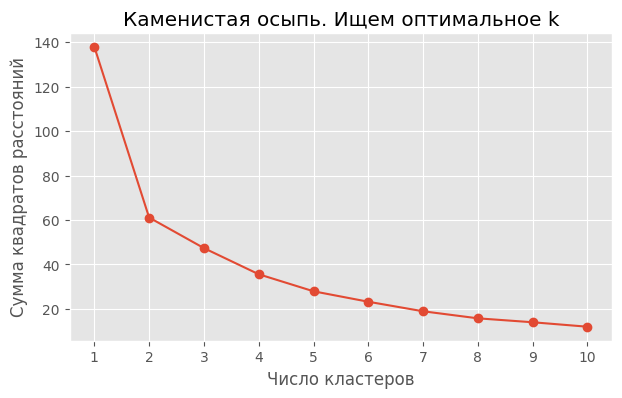

In [6]:
K = range(1, 11)
models = [KMeans(n_clusters=k, random_state=42, max_iter=300, n_init=10, tol=0.0001).fit(X) for k in K]
dist = [model.inertia_ for model in models]

plt.figure(figsize=(7, 4))
plt.plot(K, dist, marker="o")
plt.xticks(list(K))
plt.xlabel("Число кластеров")
plt.ylabel("Сумма квадратов расстояний")
plt.title("Каменистая осыпь. Ищем оптимальное k")
plt.show()

In [7]:
silhouette = {k: silhouette_score(X, models[k - 1].labels_) for k in range(2, 11)}
pd.DataFrame({"k": list(silhouette), "silhouette": list(silhouette.values())}).round(3)

,k,silhouette
0,2,0.470
1,3,0.388
2,4,0.340
3,5,0.369
4,6,0.373
5,7,0.368
6,8,0.406
7,9,0.364
8,10,0.401


На графике заметно сильное уменьшение инерции при переходе от одного к двум кластерам, затем снижение становится более плавным. По коэффициенту силуэта лучший из рассмотренных вариантов — **2 кластера**. Однако для более подробной интерпретации экономических различий рассмотрим также **3 кластера**: это позволяет отдельно выделить города с относительно небольшим числом рабочих часов и невысокими зарплатами. Выбор трёх кластеров здесь интерпретационный, а не однозначный оптимум.

### Кластеризация при k = 3

In [8]:
model = KMeans(n_clusters=3, random_state=42, max_iter=300, n_init=10, verbose=0, tol=0.0001)
model.fit(X)
print("Число итераций:", model.n_iter_)
print("Инерция:", round(model.inertia_, 2))
print("Силуэт:", round(silhouette_score(X, model.labels_), 3))

Число итераций: 4
Инерция: 47.36
Силуэт: 0.388


In [9]:
print("Координаты центров в стандартизованном пространстве:")
pd.DataFrame(model.cluster_centers_, columns=df.columns).round(2)

Координаты центров в стандартизованном пространстве:


,Work,Price,Salary
0,-0.14,-0.91,-0.94
1,-0.53,0.70,0.80
2,1.47,-0.75,-0.96


### Результаты кластеризации

In [10]:
df_result = df.copy()
df_result["cluster"] = model.labels_
df_result["cluster"].sort_values().to_frame()

,cluster
City,
Athens,0
Buenos_Aires,0
Nicosia,0
Nairobi,0
Mexico_City,0
Lisbon,0
Lagos,0
Johannesburg,0
Rio_de_Janeiro,0


In [11]:
print("Размеры кластеров:")
df_result.groupby("cluster").size()

Размеры кластеров:


cluster
0    11
1    25
2    10
dtype: int64

In [12]:
print("Средние значения признаков по кластерам:")
df_result.groupby("cluster")[["Work", "Price", "Salary"]].mean().round(2)

Средние значения признаков по кластерам:


,Work,Price,Salary
cluster,,,
0,1855.45,50.78,16.59
1,1789.24,84.97,59.03
2,2133.50,54.17,16.08


In [13]:
for cluster, group in df_result.groupby("cluster"):
    print(f"Кластер {cluster} ({len(group)} городов):")
    print(", ".join(group.index))
    print()

Кластер 0 (11 городов):
Athens, Buenos_Aires, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul

Кластер 1 (25 городов):
Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich

Кластер 2 (10 городов):
Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Taipei, Tel_Aviv



Средние значения в предыдущей таблице — это центры кластеров в исходных единицах измерения. Номера кластеров условны и не задают порядок их качества.

### Визуализация кластеров

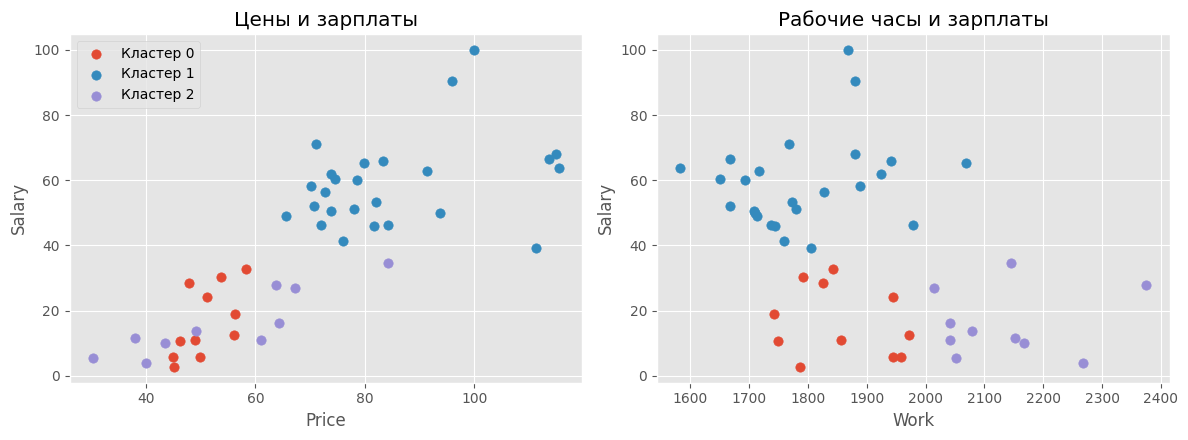

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for cluster, group in df_result.groupby("cluster"):
    axes[0].scatter(group["Price"], group["Salary"], label=f"Кластер {cluster}", s=45)
    axes[1].scatter(group["Work"], group["Salary"], label=f"Кластер {cluster}", s=45)
axes[0].set(xlabel="Price", ylabel="Salary", title="Цены и зарплаты")
axes[1].set(xlabel="Work", ylabel="Salary", title="Рабочие часы и зарплаты")
axes[0].legend()
plt.tight_layout()
plt.show()

### Сравнение с разбиением на 2 кластера

In [15]:
model_2 = KMeans(n_clusters=2, random_state=42, max_iter=300, n_init=10).fit(X)
df_2 = df.copy()
df_2["cluster"] = model_2.labels_
print("Размеры кластеров:")
print(df_2.groupby("cluster").size())
df_2.groupby("cluster")[["Work", "Price", "Salary"]].mean().round(2)

Размеры кластеров:
cluster
0    21
1    25
dtype: int64


,Work,Price,Salary
cluster,,,
0,1987.86,52.40,16.35
1,1789.24,84.97,59.03


### Вывод
После удаления двух наблюдений с пропусками кластеризация проведена по 46 городам. Стандартизация позволила учитывать все три экономических показателя на сопоставимой шкале.

При **k = 3** выделяются следующие группы:

- **Кластер 0:** сравнительно невысокие цены и зарплаты при среднем количестве рабочих часов.
- **Кластер 1:** более высокие цены и зарплаты при сравнительно меньшем количестве рабочих часов.
- **Кластер 2:** большое количество рабочих часов при относительно низких ценах и зарплатах.

Разбиение на **2 кластера** лучше по коэффициенту силуэта, то есть группы получаются более отделёнными друг от друга. Разбиение на **3 кластера** позволяет получить более подробную интерпретацию, выделив две группы городов с невысокими зарплатами, различающиеся прежде всего рабочими часами. Следовательно, выбор числа кластеров зависит не только от численного критерия, но и от цели анализа.